# Лекция 7. DQN: почему оценки разлетаются и как это чинит целевая сеть

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/07-dqn-stability/lecture/lecture.ipynb)

**Главный вопрос сегодня: почему Q-сеть с буфером опыта выдаёт оценки, которых не бывает, — и как целевая сеть возвращает их на место?**

На прошлой лекции мы заменили таблицу $Q$ нейросетью и добавили буфер опыта: шест стал стоять в несколько раз дольше, но оценки $Q$ ушли в тысячи. Сегодня найдём причину на примере из двух состояний и уберём её одной добавкой — целевой сетью. Q-сеть + буфер опыта + целевая сеть — это **DQN** (Deep Q-Network). В конце тем же алгоритмом посадим лунный модуль.

1. Где мы остановились: шест стоит, оценки неправдоподобны
2. Почему оценки разлетаются
3. Целевая сеть: цель считает медленная копия. Это и есть DQN
4. Тот же DQN сажает лунный модуль
5. Double DQN: кто выбирает действие в цели
6. Итоги и где это работает

In [1]:
# Ноутбук считается около 10–11 минут, вывод сохранён. QUICK = True — быстрый прогон с другими числами.
QUICK = False
SEEDS = range(1) if QUICK else range(3)           # номера запусков
EPISODES = 200 if QUICK else 300                  # эпизодов в одном запуске

# Служебные модули: в репозитории лежат рядом, в Google Colab скачиваются заново при каждом запуске.
import pathlib, sys, urllib.request
RAW = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main"
FILES = ("06-dqn/lecture/dqn_plots.py", "05-policy-gradient/seminar/cartpole_plots.py",
         "07-dqn-stability/lecture/dqn_core.py", "07-dqn-stability/lecture/dqn7_plots.py",
         "07-dqn-stability/lecture/lander.py", "07-dqn-stability/lecture/lander_results.npz")
for file in FILES:
    local = pathlib.Path("../..") / file
    if local.exists():
        sys.path.append(str(local.parent))
    else:
        urllib.request.urlretrieve(f"{RAW}/{file}", pathlib.Path(file).name)

In [2]:
import time
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
from dqn_core import *            # код прошлой лекции (make_qnet, epsilon_greedy, to_tensors, td_targets, q_of, q_max, train_qnet) и обвязка опытов
from dqn_plots import make_cartpole, play_greedy
from dqn7_plots import *          # схемы и картинки этой лекции
from lander import train_lander, test_lander, load_lander      # лунный модуль (раздел 4)
from cartpole_plots import animate_cartpole
torch.set_num_threads(1)          # маленькой сети один поток быстрее
start_time = time.time()

## 1. Где мы остановились: шест стоит, оценки неправдоподобны

**Главная идея: Q-сеть с буфером опыта держит шест долго, но её оценки $Q$ уходят далеко за возможный предел.**

Что мы собрали на прошлой лекции:

* **Q-сеть** получает состояние CartPole — четыре числа — и выдаёт два: $Q_\theta(s, \leftarrow)$ и $Q_\theta(s, \rightarrow)$; $\theta$ — её веса.
* **Буфер опыта** — журнал переходов $(s, a, r, s')$. Шаг обучения делается на пачке из 64 случайных переходов.
* **Цель** для каждого перехода — как в Q-learning: $y = r + \gamma \max_{a'} Q_\theta(s', a')$; если шест упал, цель — просто $r$. Шаг градиента уменьшает ошибку $\big(y - Q_\theta(s, a)\big)^2$.

На схеме — один шаг такого обучения. Красная стрелка — тема сегодняшней лекции: цель считает та же сеть, которую мы учим.

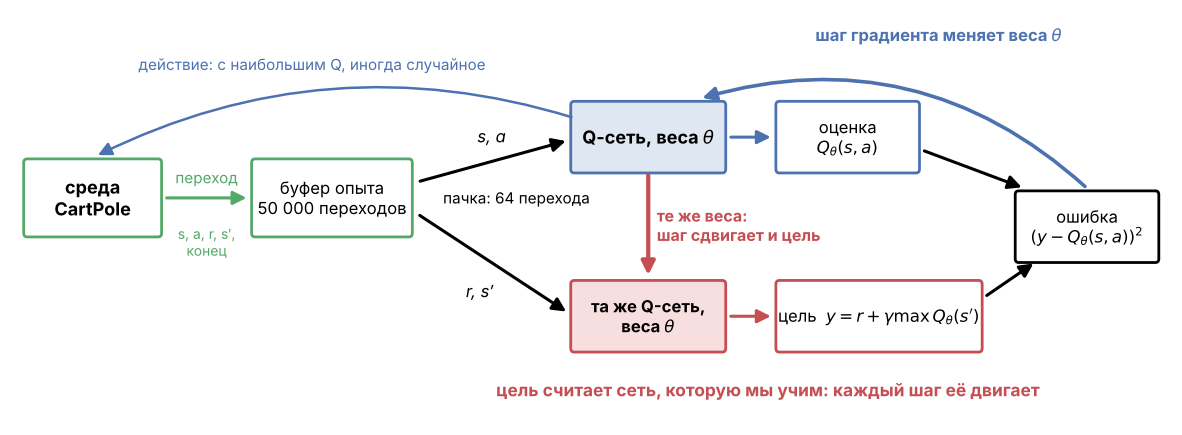

In [3]:
draw_dqn_scheme(target=False)
plt.show()

**Вопрос 1.** Пока шест стоит, агент получает $+1$ за шаг; $\gamma = 0.99$, эпизод не длиннее 500 шагов. После обучения сеть оценила стартовое состояние: $\max_a Q = 3698$. Может ли ценность старта быть такой?

* **A.** да, если шест стоит очень долго;
* **B.** нет: больше 100 не бывает;
* **C.** нет: больше 500 не бывает — в эпизоде 500 шагов;
* **D.** да: $Q$ — условные очки, а не сумма наград.

Повторим обучение прошлой лекции: по три запуска из 300 эпизодов с буфером и, для сравнения, без него — «по шагу подряд», когда сеть учится на одном только что сделанном переходе. Смотрим, сколько шагов стоит шест и какова оценка старта.

вариант          шест после 100 эпизодов, шагов   наибольшая оценка старта      (число — один запуск)
по шагу подряд   83, 75, 52                       75, 98, 58
буфер            348, 331, 206                    1584, 3698, 210279


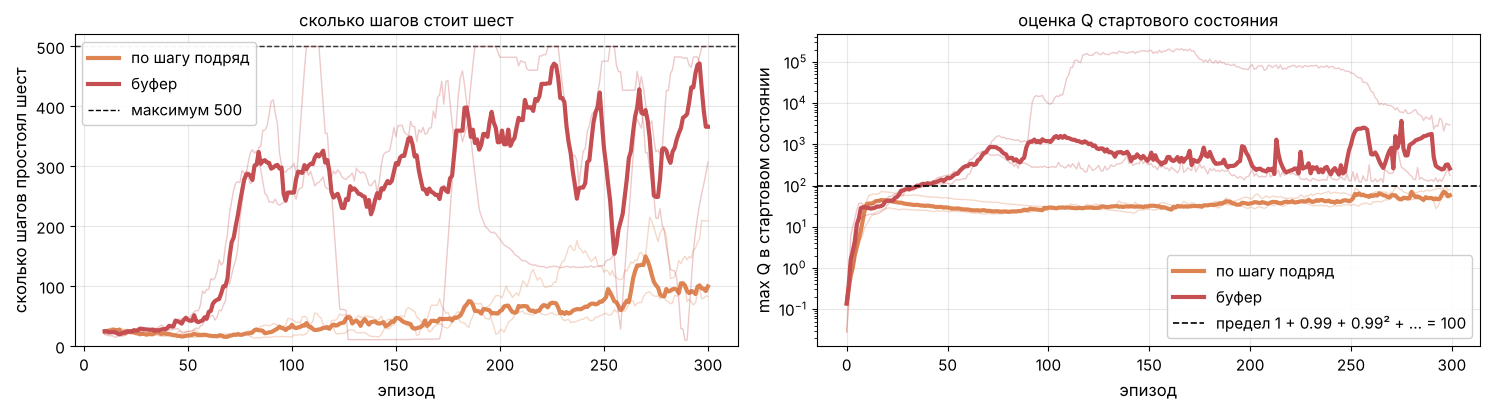

In [4]:
lengths, q_start, nets = {}, {}, {}        # результаты по названию варианта: длины эпизодов, оценки старта, сети
for name, replay in (("по шагу подряд", False), ("буфер", True)):
    lengths[name], q_start[name], nets[name] = train_runs(train_qnet, SEEDS, replay=replay, episodes=EPISODES)

print_summary(lengths, q_start)
plot_length_and_q(lengths, q_start)
plt.show()

Ответ **B — нет, больше 100 не бывает**. Даже если шест стоит вечно, сумма наград с дисконтом равна $1 + 0.99 + 0.99^2 + \dots = \dfrac{1}{1 - 0.99} = 100$. Вариант с 500 забывает про дисконт.

С буфером шест стоит 206–348 шагов против 52–83 без него (среднее по эпизодам после сотого). Но оценка старта во всех трёх запусках с буфером ушла за предел: до 1584, 3698 и 210 279. Без буфера она осталась в пределах: 58–98.

**Одной строкой:** с буфером опыта Q-сеть учится быстро, но её оценки $Q$ уходят далеко за предел 100.

## 2. Почему оценки разлетаются

**Главная идея: цель считает та же сеть, которую мы учим, — шаг к цели поднимает и саму цель.**

Самый маленький пример, где это видно (Саттон и Барто, раздел 11.2). Состояний два, все награды 0 — настоящая ценность обоих состояний 0. Оценки задаёт один вес $w$: $\hat v(1) = w$, $\hat v(2) = 2w$ — как у сети, где одни веса отвечают за много состояний. В данных только переход $1 \to 2$. Обновление — как у Q-сети: цель $= 0 + \gamma\,\hat v(2) = 1.8\,w$ при $\gamma = 0.9$, шаг $w \leftarrow w + 0.1\,(1.8\,w - w)$.

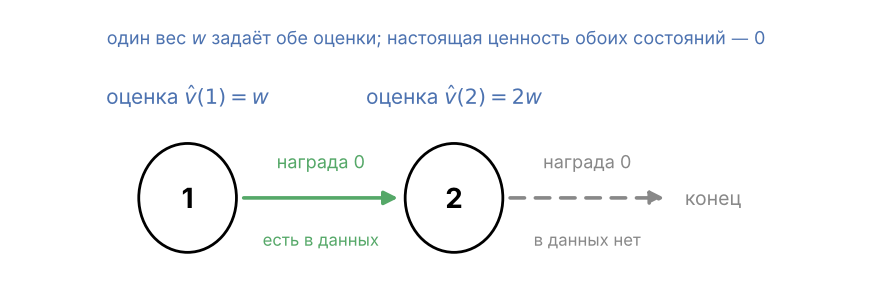

In [5]:
draw_two_states_scheme()
plt.show()

**Вопрос 2.** Начинаем с $w = 1$ и делаем 100 таких шагов. Что будет с оценкой $\hat v(1) = w$?

* **A.** придёт к 0 — награды же нулевые;
* **B.** останется около 1;
* **C.** вырастет до тысяч;
* **D.** будет колебаться вокруг 0.

Первые 12 шагов. Слева наш пример; справа то же самое, но оценки хранит таблица — у состояния 2 своё число, от $w$ оно не зависит.

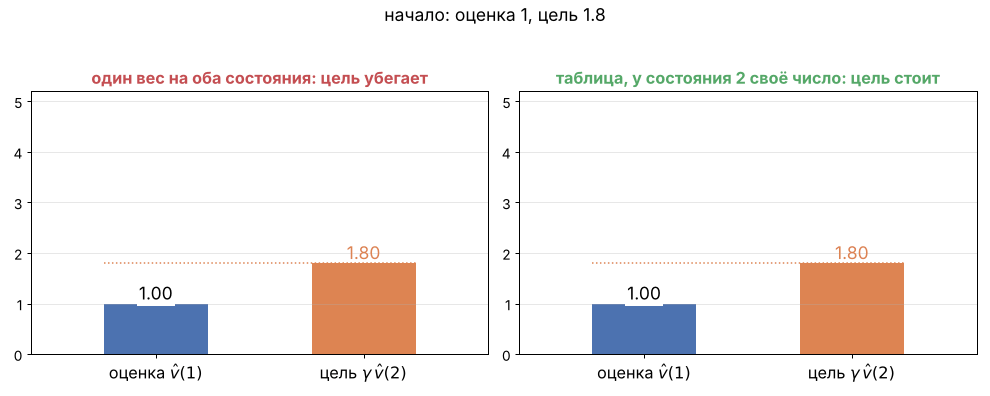

Ответ **C — вырастет до тысяч**. Каждый шаг умножает $w$ на $1.08$, за 100 шагов это $1.08^{100} \approx 2200$ — хотя наград нет вовсе. Вес $w$ поднимает обе оценки, вторую вдвое сильнее, поэтому цель $1.8\,w$ всегда впереди оценки $w$. В таблице цель от шага не зависит, и оценка просто приходит к ней.

**Когда так бывает.** Нужны три условия сразу, их называют **смертельной триадой** (deadly triad):

1. **аппроксимация** — одни веса задают оценки многих состояний;
2. **бутстрэппинг** — в цели стоит своя же оценка;
3. **off-policy** — данные собрала не та стратегия, которую оцениваем.

Без любого из трёх оценки не разлетаются. Третье условие Q-сети добавил буфер: в нём лежат переходы всех прошлых версий стратегии. Пока сеть училась по шагу подряд, её оценки за предел 100 не выходили.

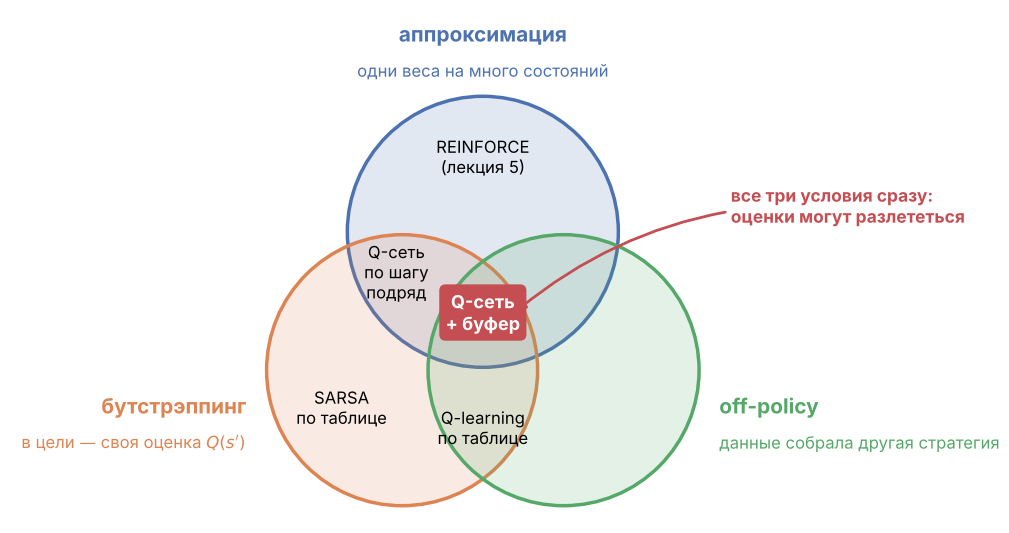

In [6]:
draw_triad()
plt.show()

> **Простыми словами.** Это как догонять собственную тень: шагаешь к ней — она отодвигается.

**Одной строкой:** общие веса + своя оценка в цели + старые данные — и оценки могут расти без единой награды.

## 3. Целевая сеть: цель считает медленная копия. Это и есть DQN

**Главная идея: цель $y$ считает не обучаемая сеть, а её копия, которая сдвигается к оригиналу на 1 % за шаг, — шаг обучения цель больше не поднимает.**

В ошибке веса $\theta$ стоят дважды — в цели и в оценке:

$$
\text{ошибка} \;=\; \big(\underbrace{r + \gamma \max_{a'} Q_\theta(s', a')}_{\text{цель } y} \;-\; Q_\theta(s, a)\big)^2 .
$$

Заведём второй набор весов $\bar\theta$ — копию сети — и будем считать цель им:

$$
y \;=\; r + \gamma \max_{a'} Q_{\bar\theta}(s', a'), \qquad\quad \bar\theta \;\leftarrow\; 0.99\,\bar\theta + 0.01\,\theta \ \ \text{после каждого шага}.
$$

Шаг градиента меняет $\theta$ и не трогает $\bar\theta$ — цель для него готовое число. Чтобы цель не застыла на необученной сети, копия после каждого шага сдвигается к $\theta$ на 1 % — отстаёт от неё примерно на $1 / 0.01 = 100$ шагов. Это **целевая сеть** (target network). На схеме изменилась одна деталь:

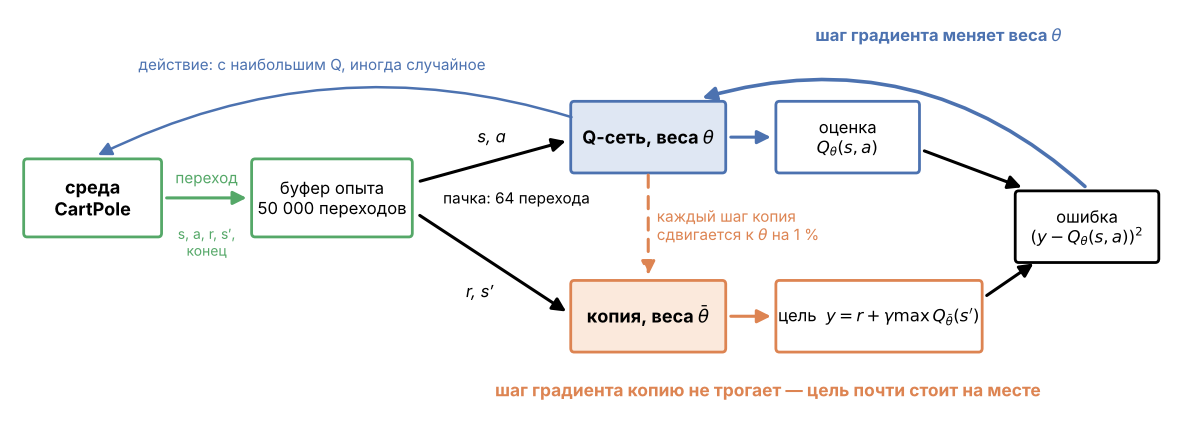

In [7]:
draw_dqn_scheme(target=True)
plt.show()

> **Простыми словами.** Раньше мишень отпрыгивала после каждого выстрела. Теперь она ползёт так медленно, что в неё можно целиться.

В коде — три новые строки, они помечены `# ← новое`. Остальное — цикл обучения прошлой лекции.

In [8]:
def soft_update(target_net, qnet, tau=0.01):
    # θ̄ ← (1 − τ) θ̄ + τ θ для каждого веса: копия сдвигается к основной сети на 1 %
    with torch.no_grad():
        for w_copy, w in zip(target_net.parameters(), qnet.parameters()):
            w_copy.copy_((1 - tau) * w_copy + tau * w)


def train_dqn(seed, replay=True, episodes=EPISODES):
    rng, env, qnet = np.random.default_rng(seed), make_cartpole(), make_qnet(seed)
    target_net = make_qnet(seed)                                       # ← новое: копия сети, веса θ̄
    opt = torch.optim.Adam(qnet.parameters(), lr=1e-3)
    buffer = deque(maxlen=50_000)                                      # буфер опыта
    step, lengths, q_start = 0, [], []
    for episode in range(episodes):
        s, _ = env.reset(seed=seed * 10_000 + episode)
        q_start.append(q_max(qnet, s))                                 # оценка старта эпизода — число
        for t in range(1, 501):
            # 1. шаг в среде, переход — в буфер
            a = epsilon_greedy(qnet, s, eps=max(0.01, 1 - step / 5000), rng=rng)
            s2, r, terminated, truncated, _ = env.step(a)
            buffer.append((s, a, np.float32(r), s2, np.float32(terminated)))
            # 2. пачка: 64 случайных перехода из буфера (без буфера — один последний)
            picked = [buffer[i] for i in rng.integers(len(buffer), size=64)] if replay else [buffer[-1]]
            S, A, R, S2, D = to_tensors(picked)                        # S, S2 — тензоры 64 × 4; A, R, D — по 64 числа
            # 3. цель и шаг градиента
            y = td_targets(target_net, R, S2, D)                       # ← новое: цель считает копия
            loss = ((y - q_of(qnet, S, A)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            # 4. копия сдвигается к основной сети
            soft_update(target_net, qnet)                              # ← новое
            step += 1; s = s2
            if terminated or truncated:
                break
        lengths.append(t)
    return np.array(lengths), np.array(q_start), qnet                  # длины эпизодов, оценки старта, сеть

**Вопрос 3.** Четыре варианта: буфер есть или нет × целевая сеть есть или нет. Какой будет держать шест дольше всех и при этом не разгонит оценки $Q$ до тысяч?

* **A.** только буфер;
* **B.** только целевая сеть;
* **C.** буфер и целевая сеть вместе;
* **D.** без буфера и без целевой сети.

Два варианта без целевой сети уже обучены в разделе 1. Обучим два с целевой сетью.

вариант                      шест после 100 эпизодов, шагов   наибольшая оценка старта      (число — один запуск)
по шагу подряд               83, 75, 52                       75, 98, 58
буфер                        348, 331, 206                    1584, 3698, 210279
целевая сеть                 33, 26, 32                       45, 28, 36
буфер + целевая сеть (DQN)   273, 416, 387                    119, 114, 131


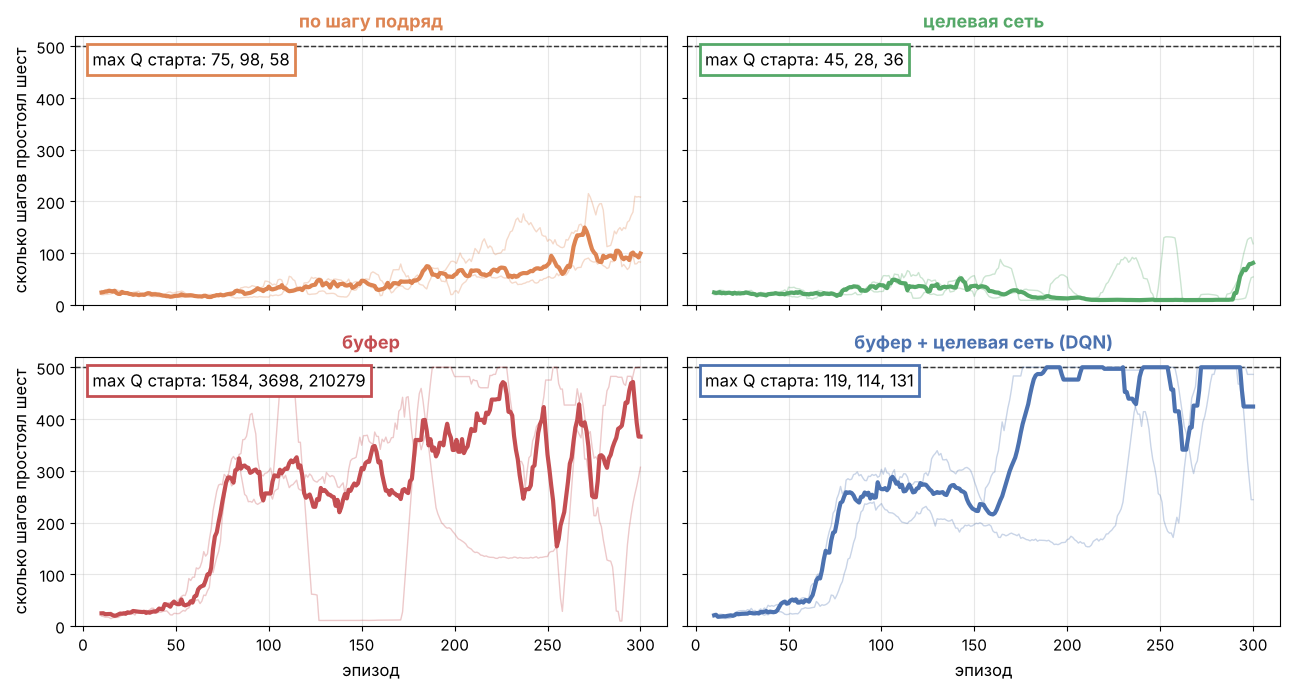

In [9]:
DQN = "буфер + целевая сеть (DQN)"
for name, replay in (("целевая сеть", False), (DQN, True)):
    lengths[name], q_start[name], nets[name] = train_runs(train_dqn, SEEDS, replay=replay)

print_summary(lengths, q_start)
plot_four_variants(lengths, q_start)
plt.show()

Ответ **C — буфер и целевая сеть вместе**. DQN держит шест 273–416 шагов, а наибольшая оценка старта — 114–131: рядом с пределом 100, а не тысячи. Один буфер держит шест почти так же долго (206–348), но оценки у него — тысячи и сотни тысяч. Одна целевая сеть почти не учится: 26–33 шага.

> **Простыми словами.** Буфер даёт разнообразные примеры, целевая сеть — почти неподвижную цель. По отдельности не работает: без буфера примеров мало и они однообразные, а цель к тому же запаздывает; без целевой сети цель убегает.

Целевая сеть не убирает ни одного из трёх условий — она замедляет рост. В примере «w и 2w» с такой копией оценка тоже растёт, только в сотни раз медленнее. В CartPole этого хватает: у переходов, где шест упал, цель — просто $r = 1$, без своей оценки.

Так держит шест сеть из лучшего запуска DQN: в каждом состоянии — действие с наибольшим $Q$, без случайных шагов.

In [10]:
best = nets[DQN][best_run(lengths[DQN])]                 # сеть запуска с самыми длинными последними эпизодами
states = play_greedy(best, seed=0)                       # эпизод без случайных действий: список состояний
animate_cartpole(states, path="dqn_cartpole.gif", every=6, dpi=100)
print("шест простоял шагов:", len(states) - 1)

шест простоял шагов: 500


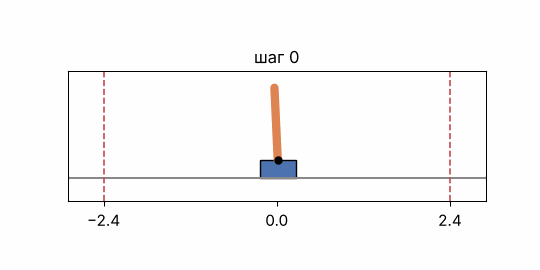

**Весь DQN в шести шагах** — их делает `train_dqn`, и они же нарисованы на схеме:

1. выбрать действие: с наибольшим $Q_\theta$, изредка случайное;
2. сделать шаг, переход — в буфер;
3. взять из буфера случайную пачку;
4. посчитать цель $y$ копией $\bar\theta$;
5. сделать шаг градиента по $\big(y - Q_\theta(s, a)\big)^2$;
6. сдвинуть копию к $\theta$ на 1 %.

**Одной строкой:** DQN = Q-сеть + буфер опыта (разнообразные данные) + целевая сеть (цель, которую шаг обучения не поднимает).

## 4. Тот же DQN сажает лунный модуль

**Главная идея: в DQN нет ничего про шест — тот же алгоритм учится управлять другим физическим объектом, меняются только размеры сети.**

Задача — посадить модуль на площадку. Это среда `LunarLander` из Gymnasium, движение модуля считает физический движок Box2D.

* **Состояние** — 8 чисел: координаты $x$ и $y$, две скорости, угол наклона, угловая скорость и два признака «опора касается грунта».
* **Действия** — 4: ничего не делать, включить левый, главный или правый двигатель.
* **Награда** — плюс за приближение к площадке и гашение скорости, минус за наклон и расход топлива; $+100$ за посадку, $-100$ за аварию.
* **Конец эпизода** — модуль сел, разбился или улетел за край.

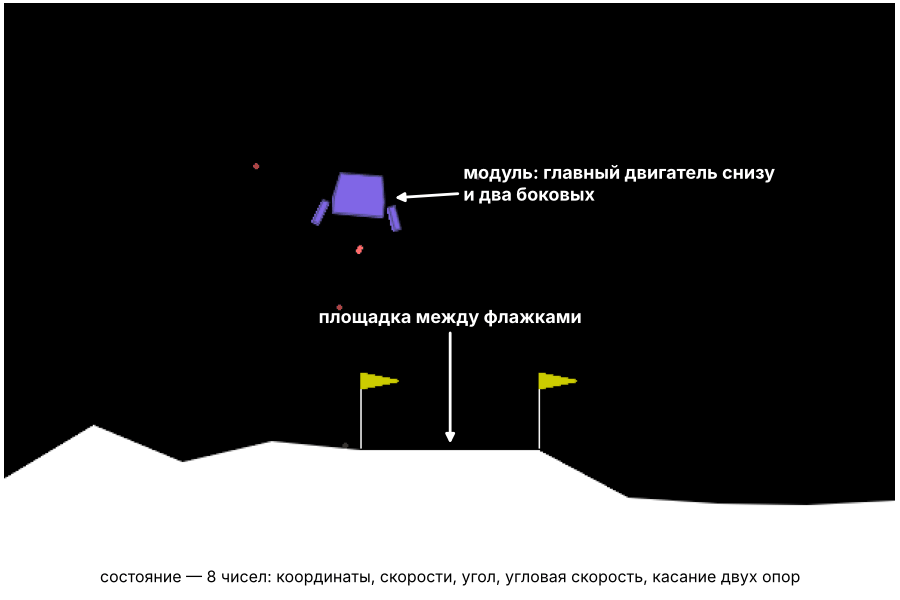

**Вопрос 4.** Что придётся поменять в `train_dqn`, чтобы вместо шеста учиться сажать модуль?

* **A.** почти всё: шест и модуль — разные задачи;
* **B.** формулу цели $y$: награды здесь другие;
* **C.** размеры сети: 8 чисел на входе, 4 на выходе;
* **D.** убрать буфер: эпизоды у модуля длиннее.

Ответ **C — размеры сети**. Буфер, цель от копии сети и сдвиг копии на 1 % — те же строки. Отличия:

| | шест | лунный модуль |
|---|---|---|
| Q-сеть | 4 → 64 → 64 → 2 | 8 → 64 → 64 → 4 |
| эпизодов обучения | 300 | 600 |
| доля случайных действий падает до 1 % за | 5000 шагов | 20 000 шагов |

Цикл обучения — `train_lander` в `lander.py`, те же четыре блока. Одно обучение идёт около 6 минут, поэтому ячейка ниже по умолчанию берёт сохранённый результат этого же вызова; с `TRAIN_LANDER = True` она обучит модуль заново.

обучение: первые 50 эпизодов в среднем -140, последние 50 — 248
20 новых эпизодов: в среднем 270, не меньше 200 — в 19 из 20


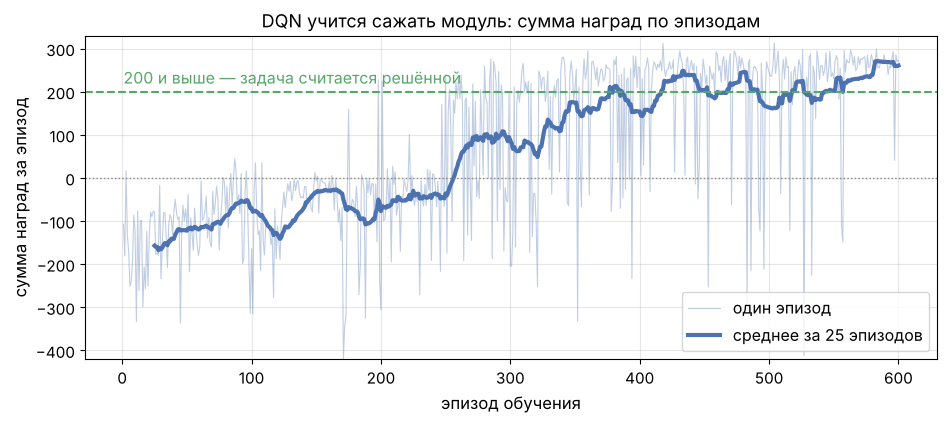

In [3]:
TRAIN_LANDER = False     # True — обучить заново: около 6 минут на запуск, нужен пакет gymnasium[box2d]

if TRAIN_LANDER:
    returns, lander_net = train_lander(seed=0, episodes=600)     # суммы наград по эпизодам и обученная сеть
    tests = test_lander(lander_net, episodes=20)                 # 20 новых эпизодов без случайных действий
else:
    returns, tests = load_lander("dqn", seed=0)                  # сохранённый результат этого же вызова

print(f"обучение: первые 50 эпизодов в среднем {returns[:50].mean():.0f}, последние 50 — {returns[-50:].mean():.0f}")
print(f"20 новых эпизодов: в среднем {tests.mean():.0f}, не меньше 200 — в {(tests >= 200).sum()} из 20")
plot_lander_returns(returns, title="DQN учится сажать модуль: сумма наград по эпизодам")
plt.show()

Первые 50 эпизодов модуль набирает в среднем −140: падает и разбивается. Последние 50 — в среднем 248. На 20 новых эпизодах без случайных действий сеть набрала в среднем 270, и в 19 из 20 — не меньше 200.

Один и тот же старт: слева эта сеть до обучения, справа — после. Анимация записана заранее.

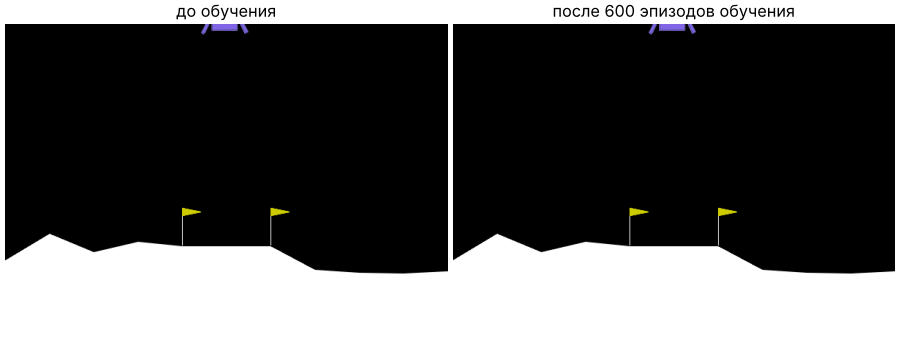

> **Простыми словами.** Алгоритму не нужны формулы физики: агент получает числа, пробует действия и учится по наградам. Поэтому один и тот же код управляет и шестом, и посадочным модулем.

**Одной строкой:** DQN — общий алгоритм: чтобы управлять другим объектом, достаточно поменять размеры сети.

## 5. Double DQN: кто выбирает действие в цели

**Главная идея: цель DQN берёт наибольшую из неточных оценок, а наибольшей чаще оказывается та, что завышена по ошибке. Double DQN спрашивает основную сеть, какое действие лучше, а копию — сколько оно стоит.**

Взять $\max$ — значит выбрать действие $a^*$ с наибольшей оценкой и взять эту оценку. Два метода отличаются только тем, какая сеть выбирает $a^*$:

$$
\begin{aligned}
\text{DQN:} \quad & a^* = \arg\max_{a'} Q_{\bar\theta}(s', a') \ \ \text{(выбирает копия)}, & y &= r + \gamma\, Q_{\bar\theta}(s', a^*); \\
\text{Double DQN:} \quad & a^* = \arg\max_{a'} Q_{\theta}(s', a') \ \ \text{(выбирает основная сеть)}, & y &= r + \gamma\, Q_{\bar\theta}(s', a^*).
\end{aligned}
$$

**Пример.** В состоянии $s'$ два действия, настоящая ценность обоих — 10. Копия выдаёт 12 и 9.5, основная сеть — 9 и 11.

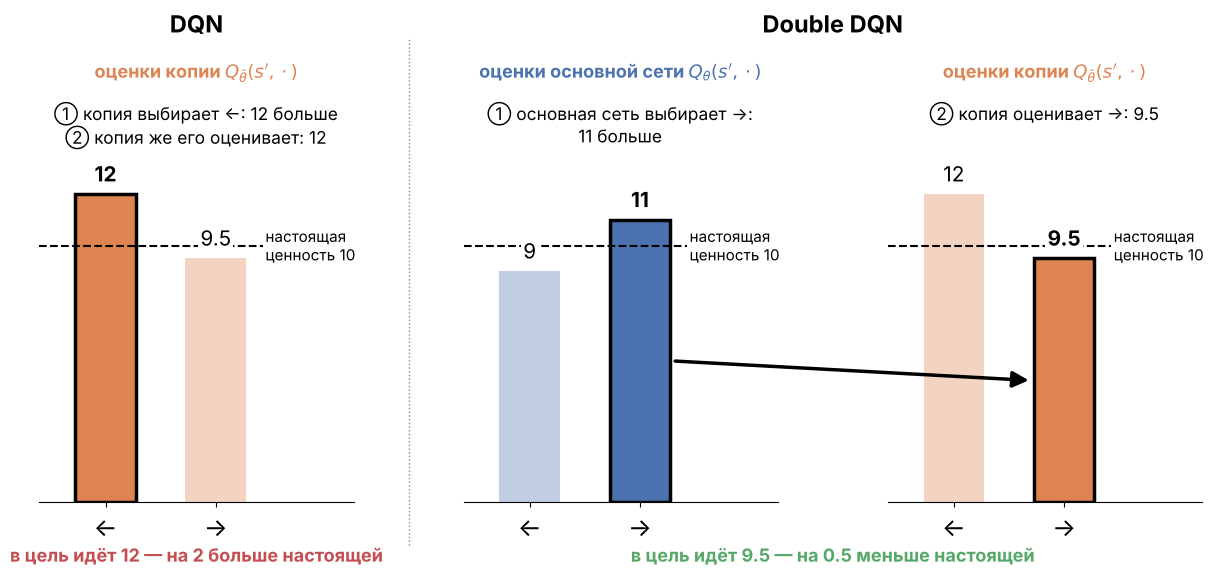

In [11]:
draw_double_dqn(copy=(12, 9.5), main=(9, 11), true=10)
plt.show()

DQN взял 12: копия выбрала ← как раз потому, что завысила его оценку. В Double DQN выбирала основная сеть, и в цель ушла оценка копии для другого действия — 9.5.

**Вопрос 5.** Настоящая ценность обоих действий — 10. Копия ошибается случайно: в среднем на 0, обычно примерно на единицу. Что в среднем получит DQN, если повторить это много раз?

* **A.** ровно 10: ошибки вверх и вниз гасят друг друга;
* **B.** больше 10;
* **C.** меньше 10.

In [3]:
rng = np.random.default_rng(0)
copy = 10 + rng.normal(size=(100_000, 2))      # 100 000 повторов × 2 действия: оценки копии, настоящая ценность 10
main = 10 + rng.normal(size=(100_000, 2))      # оценки основной сети для тех же действий, ошибки у неё свои
double = np.where(main.argmax(axis=1) == 0, copy[:, 0], copy[:, 1])    # основная сеть выбирает, копия оценивает
print(f"в среднем: одна оценка {copy[:, 0].mean():.2f}, цель DQN {copy.max(axis=1).mean():.2f}, цель Double DQN {double.mean():.2f}")

в среднем: одна оценка 10.00, цель DQN 10.57, цель Double DQN 10.00


Ответ **B — больше 10**: в среднем 10.57, потому что $\max$ всегда берёт оценку с большей ошибкой. У Double DQN получается 10.00: ошибка копии не связана с выбором основной сети. В настоящем DQN ошибки сети и копии похожи, поэтому завышение уменьшается, но не исчезает.

В цикле обучения меняется одна строка — вместо `td_targets(target_net, R, S2, D)`:

In [13]:
def double_targets(qnet, target_net, R, S2, D, gamma=0.99):
    with torch.no_grad():
        best = qnet(S2).argmax(dim=1)                                  # 64 номера действий: выбирает основная сеть
        return R + gamma * (1 - D) * q_of(target_net, S2, best)        # 64 числа: оценивает копия; (1 − D) — если шест упал, цель просто r

**Обучение.** Тот же лунный модуль, что в разделе 4: по три запуска DQN и Double DQN, отличается только эта строка (параметр `double`).

DQN        последние 50 эпизодов: в среднем 214;  на новых эпизодах не меньше 200 — 55 из 60
Double DQN последние 50 эпизодов: в среднем 230;  на новых эпизодах не меньше 200 — 49 из 60


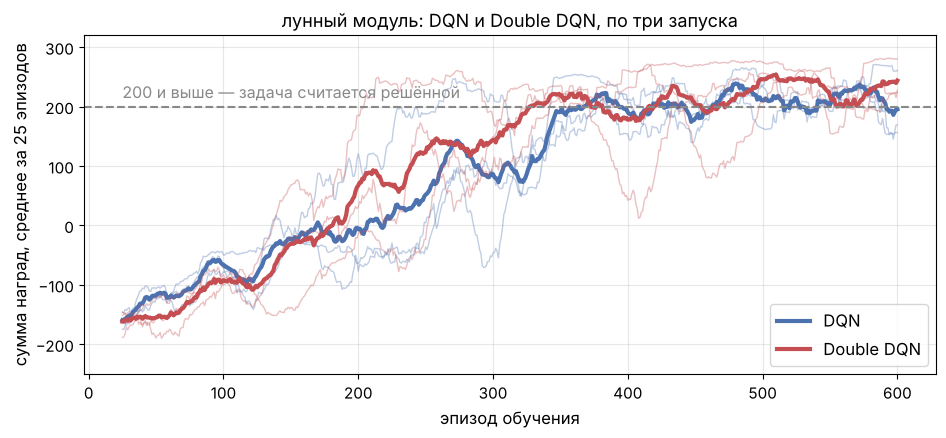

In [4]:
curves, tests = {}, {}                   # по названию варианта: суммы наград (запуски × эпизоды) и проверки (запуски × 20)
for name, double in (("DQN", False), ("Double DQN", True)):
    if TRAIN_LANDER:
        runs = [train_lander(seed, episodes=600, double=double) for seed in range(3)]     # список пар (суммы наград, сеть)
        curves[name] = np.array([returns for returns, net in runs])
        tests[name] = np.array([test_lander(net, episodes=20) for returns, net in runs])
    else:
        curves[name], tests[name] = load_lander("double" if double else "dqn")            # сохранённые три запуска
    print(f"{name:10s} последние 50 эпизодов: в среднем {curves[name][:, -50:].mean():.0f};"
          f"  на новых эпизодах не меньше 200 — {(tests[name] >= 200).sum()} из {tests[name].size}")
plot_lander_compare(curves, title="лунный модуль: DQN и Double DQN, по три запуска")
plt.show()

Оба варианта сажают модуль, и разница между ними — в пределах разброса трёх запусков: последние 50 эпизодов обучения в среднем 214 у DQN и 230 у Double DQN, на новых эпизодах не меньше 200 набирают 55 и 49 посадок из 60. Заметный выигрыш Double DQN даёт там, где действий много: в играх Atari (до 18 действий) он уменьшил завышение оценок и улучшил игру (van Hasselt и др., 2016).

Другие улучшения DQN: Prioritized replay — из буфера чаще берутся переходы с большой ошибкой; n-step — в цели несколько настоящих наград подряд; Rainbow — всё это вместе с Double DQN.

> **Простыми словами.** Если из нескольких неточных оценок всегда брать наибольшую, ошибаться будешь в одну сторону — вверх. Поэтому выбирает одна сеть, а число называет другая.

**Одной строкой:** Double DQN убирает завышение от $\max$: действие выбирает основная сеть, оценивает копия.

## 6. Итоги и где это работает

1. **Q-сеть с буфером опыта** держит шест 206–348 шагов, но оценка старта доходит до 210 279 при пределе 100.
2. **Причина — цель считает сама обучаемая сеть:** шаг к цели поднимает и цель. В примере «w и 2w» оценка за 100 шагов выросла с 1 до 2200 при нулевых наградах.
3. **Смертельная триада:** общие веса, своя оценка в цели, данные другой стратегии. Опасны только все три вместе; третье условие добавил буфер.
4. **Целевая сеть** — копия, которая подтягивается к основной сети на 1 % за шаг и считает цель. **DQN = Q-сеть + буфер + целевая сеть:** шест стоит 273–416 шагов, наибольшая оценка старта 114–131; лучшая сеть без случайных шагов держит шест все 500 шагов.
5. **DQN — общий алгоритм.** С сетью 8 → 64 → 64 → 4 тот же код учится сажать лунный модуль: средняя сумма наград выросла с −140 до 248, на новых эпизодах 19 посадок из 20 набирают не меньше 200.
6. **Double DQN:** наибольшая из неточных оценок в среднем завышена (10.57 при настоящей ценности 10), поэтому действие в цели выбирает основная сеть, а оценивает копия. Лунный модуль оба варианта сажают одинаково хорошо.

**Где это работает.** Игры Atari: DQN (Mnih и др., 2015) одной и той же программой играл в 49 игр, глядя только на экран, и больше чем в половине из них — не хуже человека. Алгоритм тот же, что у нас: буфер опыта (на миллион переходов) и целевая сеть. Другая только сама Q-сеть — свёрточная, она читает картинку.

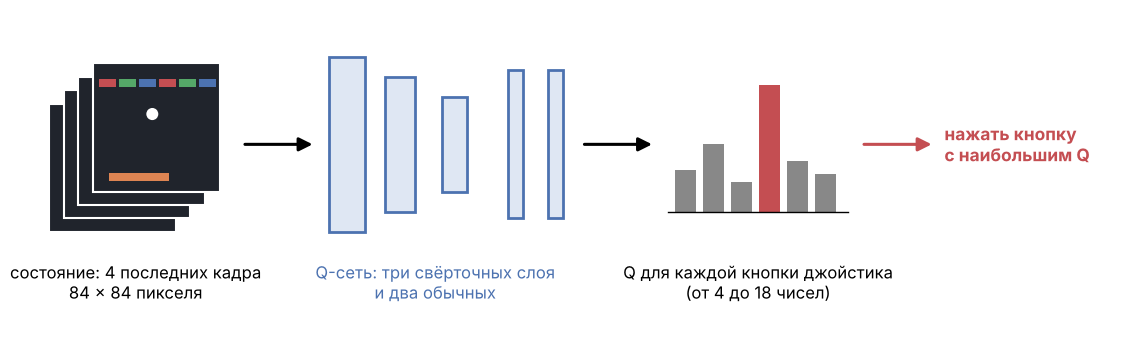

In [14]:
draw_atari_scheme()
plt.show()

> **Простыми словами — вся лекция.** Сеть, которая учится по собственным оценкам на старых данных, может поднимать эти оценки без конца. В DQN цель считает медленная копия сети — и оценки остаются возле настоящих.

Словарь лекции: **смертельная триада (аппроксимация, бутстрэппинг, off-policy), целевая сеть (target network), DQN, Double DQN**.

## Литература

* Mnih V. и др. *Human-level control through deep reinforcement learning*. Nature, 2015 — DQN на Atari.
* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд., глава 11: пример «w и 2w» — раздел 11.2, смертельная триада — раздел 11.3. [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html)
* van Hasselt H., Guez A., Silver D. *Deep reinforcement learning with double Q-learning*. AAAI, 2016 — Double DQN.
* Hessel M. и др. *Rainbow: combining improvements in deep reinforcement learning*. AAAI, 2018 — обзор улучшений DQN.
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem).

## На семинаре и дома

* **Домашка блока 3** (лекция 5: градиент стратегии и REINFORCE) — дедлайн 22 ноября, 23:59 МСК.

In [15]:
print(f"ноутбук посчитался за {(time.time() - start_time) / 60:.0f} мин")

ноутбук посчитался за 10 мин
